# UTS KLASIFIKASI

## BUSINESS UNDERSTANDING

Proyek klasifikasi tutupan lahan (Land Use Land Cover) wilayah Jawa Timur ini dikembangkan untuk merespons tingginya dinamika alih fungsi lahan akibat urbanisasi dan pertumbuhan ekonomi. Mengingat pemantauan manual di lapangan sangat tidak efisien, sistem ini memanfaatkan citra satelit Sentinel-2 untuk memetakan permukaan bumi secara otomatis, cepat, dan berkala.

Dengan mengekstrak nilai spektral dari Band 4 (Red), Band 8A (Narrow NIR), dan Band 11 (SWIR), model Machine Learning yang dibangun mampu mengatasi kebingungan visual pada citra standar. Sistem dapat membedakan secara presisi objek-objek yang sering kali mengecoh mata manusia, seperti memisahkan hutan daratan dengan hutan mangrove pesisir, atau lahan pertanian produktif dengan area terbangun (build-up area).

Hasil akhir dari prediksi model ini disajikan dalam bentuk dashboard peta interaktif. Melalui platform ini, para pengambil kebijakan dapat langsung memfilter dan memantau distribusi lahan secara real-time demi mendukung perencanaan tata ruang serta pelestarian lingkungan yang lebih akurat.


## DATA UNDERSTANDING

Tahap Data Understanding bertujuan untuk memahami karakteristik, distribusi, dan rincian data spektral yang diekstrak, serta mengidentifikasi potensi masalah pada data sebelum masuk ke tahap pemodelan.

C:\Users\mappattiro\kal\kal\Lib\site-packages\geemap\common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/160 tiles [00:00<?]

C:\Users\mappattiro\kal\kal\Lib\site-packages\geedim\image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


Total data: 51834 baris, 9 kolom

Distribusi Kelas:
 Class
Perairan          41628
Hutan              4278
Sawah              2672
Bangunan           2389
Hutan Mangrove      867


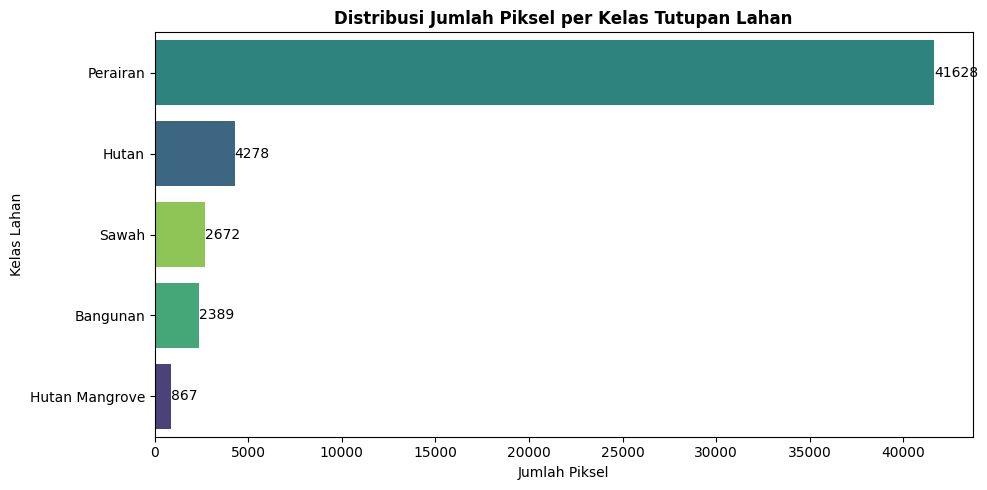

In [2]:
import os
import json
import pandas as pd
import urllib.request
import ee
import geemap
import matplotlib.pyplot as plt
import seaborn as sns

file_csv = 'dataset_training.csv'
file_tif = 'Sentinel2_Area.tif'
file_geojson = 'Update20.geojson'

# Inisialisasi API Google Earth Engine
if not (os.path.exists(file_csv) and os.path.exists(file_tif)):
    try:
        ee.Initialize()
    except Exception:
        ee.Authenticate()
        ee.Initialize()

    # Membaca data poligon sampel spasial dari GeoJSON
    with open(file_geojson, 'r') as f:
        geojson_data = json.load(f)
        
    pemetaan_kelas = {
        'Hutan Mangrove\n': 'Hutan Mangrove',
        'Hutan biasa (Forest)': 'Hutan',
        'Lautan, danau, perairan ( water body)': 'Perairan',
        'Lahan Pertanian': 'Sawah',   
        'bangunan': 'Bangunan'        
    }
    
    # Validasi dan standarisasi penamaan kelas pada poligon
    fitur_valid = []
    for feature in geojson_data['features']:
        if 'Class' in feature['properties']:
            nama_asli = feature['properties']['Class']
            if nama_asli in pemetaan_kelas:
                feature['properties']['Class'] = pemetaan_kelas[nama_asli]
                fitur_valid.append(feature)
                
    fc = ee.FeatureCollection(fitur_valid)
    roi = fc.geometry().bounds()
    
    # Akuisisi citra Sentinel-2 (6 band mentah)
    s2_base = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED") \
        .filterBounds(roi) \
        .filterDate('2025-01-01', '2026-09-30') \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
        .median() \
        .select(['B2', 'B3', 'B4', 'B8A', 'B11', 'B12'])

    # Kalkulasi penambahan indeks NDVI dan NDWI
    ndvi = s2_base.normalizedDifference(['B8A', 'B4']).rename('NDVI')
    ndwi = s2_base.normalizedDifference(['B3', 'B8A']).rename('NDWI')
    s2_final = s2_base.addBands([ndvi, ndwi])
    
    # Ekstraksi nilai piksel ke format tabular (CSV) pada skala 30m
    if not os.path.exists(file_csv):
        sampled = s2_final.sampleRegions(
            collection=fc, properties=['Class'], scale=30, tileScale=16, geometries=False
        )

        url = sampled.getDownloadURL(filetype='csv', selectors=['Class', 'B2', 'B3', 'B4', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI'])
        urllib.request.urlretrieve(url, file_csv)
        
        df_temp = pd.read_csv(file_csv).dropna()
        df_temp = df_temp.rename(columns={
            'B2': 'Band_2', 'B3': 'Band_3', 'B4': 'Band_4', 
            'B8A': 'Band_8A', 'B11': 'Band_11', 'B12': 'Band_12'
        })
        df_temp.to_csv(file_csv, index=False)

    # Pengunduhan citra raster utuh (TIF) pada skala 100m untuk efisiensi render
    if not os.path.exists(file_tif):
        geemap.download_ee_image(
            s2_final, 
            filename=file_tif, 
            scale=100,
            region=roi,
            crs='EPSG:4326'
        )

# Analisis dan visualisasi distribusi kelas data latih
df = pd.read_csv(file_csv)
distribusi = df['Class'].value_counts()

print(f"Total data: {df.shape[0]} baris, {df.shape[1]} kolom")
print("\nDistribusi Kelas:\n", distribusi.to_string())

plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', (width + 5, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Sumber Data dan Skenario Ekstraksi

Data tabular diekstrak berdasarkan sekumpulan area *Region of Interest* (ROI) berformat GeoJSON yang telah diperbarui dan tersebar di wilayah Jawa Timur. Nilai piksel diekstrak menggunakan layanan Google Earth Engine (*cloud-based*) dengan parameter ekstraksi sebagai berikut:

- **Koleksi Citra:** Sentinel-2 Level-2A (*Bottom of Atmosphere*).
- **Rentang Waktu:** 1 Januari 2025 hingga 30 September 2026.
- **Toleransi Awan:** Maksimum 50%. Reduksi awan dilakukan secara otomatis menggunakan metode *Median Reducer* (mengambil nilai spektral tengah yang paling bersih dari rentang waktu tersebut).
- **Resolusi Spasial (*Scale*):** 30 meter per piksel. Resolusi ini dipertahankan untuk memastikan objek kelas minoritas dengan area sempit (seperti Bangunan dan Sawah) tidak hilang atau tertelan oleh *grid* spasial, sehingga jumlah sampel piksel tetap melimpah dan representatif.
- **Metode Unduh:** Data diekstrak melalui URL *download* menjadi file `dataset_training.csv` untuk menghindari limitasi memori bawaan (batas 5.000 elemen) pada server Google.

### Karakteristik Fitur (Spektral Band & Indeks)

Dataset ini menggunakan 6 variabel spektral independen berupa pantulan cahaya (reflektansi) dari saluran satelit Sentinel-2, ditambah 2 fitur hasil kalkulasi indeks tutupan lahan. Pemilihan 8 fitur ini bertujuan untuk memisahkan 5 kelas lahan secara optimal:

| Nama Fitur | Fungsi Klasifikasi |
|---|---|
| Band 2 (Blue) & Band 3 (Green) | Sangat sensitif terhadap pantulan air. Kehadiran dua band ini krusial untuk membedakan kelas Perairan dengan objek gelap lain seperti bayangan atau aspal. |
| Band 4 (Red) | Menyerap klorofil tanaman secara kuat. Sangat esensial untuk mendeteksi kerapatan daun dan memisahkan vegetasi dari non-vegetasi. |
| Band 8a (Narrow NIR) | Memiliki rentang gelombang inframerah dekat yang sempit dan presisi. Mampu menembus gangguan aerosol atmosfer lebih baik dari B8 biasa, sehingga sangat akurat untuk membedakan detail vegetasi spesifik. |
| Band 11 (SWIR 1) | Sangat sensitif terhadap kelembapan tanah tingkat atas dan material penyerap panas. Menjadi fitur penegas utama untuk mengklasifikasikan area Bangunan dan Sawah kering. |
| Band 12 (SWIR 2) | Sangat sensitif terhadap genangan air di bawah tajuk (*canopy*) vegetasi. Ini adalah kunci utama pembeda antara Hutan Mangrove (lahan basah/pasang surut) dengan Hutan Biasa (lahan kering), karena air akan mematikan pantulan spektral SWIR 2. |
| NDVI | (*Normalized Difference Vegetation Index*) Secara tegas memisahkan objek vegetasi hijau (Hutan, Sawah) dengan objek non-vegetasi (Bangunan, Tanah Kosong). |
| NDWI | (*Normalized Difference Water Index*) Menghilangkan ambiguitas spektral antara Perairan asli dengan objek daratan yang gelap (seperti bayangan awan atau area padat penduduk). |

Struktur Dataset:
Total baris data : 51834
Total kolom      : 9 (1 label 'Class', 8 fitur spektral & indeks)

Distribusi Kelas:
- Perairan       : 41628 piksel
- Hutan          : 4278 piksel
- Sawah          : 2672 piksel
- Bangunan       : 2389 piksel
- Hutan Mangrove : 867 piksel

Samples Data Teratas:


,Class,Band_2,Band_3,Band_4,Band_8A,Band_11,Band_12,NDVI,NDWI
0,Hutan Mangrove,626.0,866.0,711.0,2661.5,1597.5,910.0,0.578354,-0.509001
1,Hutan Mangrove,505.0,747.5,602.0,2719.0,1642.0,841.0,0.637459,-0.568729
2,Hutan Mangrove,906.5,1056.0,609.0,603.0,453.5,264.0,-0.004950,0.273056
3,Hutan Mangrove,465.5,719.5,557.0,2721.0,1628.5,893.0,0.660159,-0.581747
4,Hutan Mangrove,472.0,686.5,569.5,2908.5,1911.5,1071.5,0.672513,-0.618081


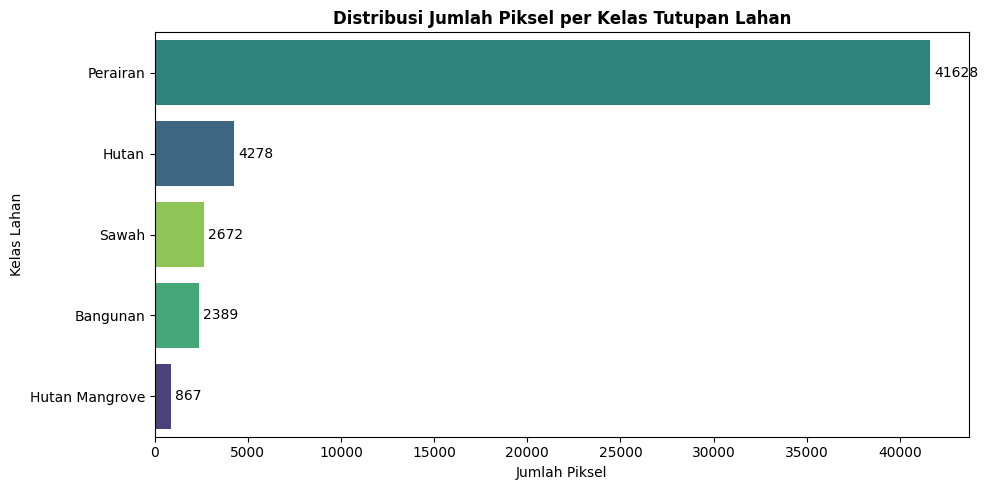

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dataset_training.csv')

baris, kolom = df.shape
print("Struktur Dataset:")
print(f"Total baris data : {baris}")
print(f"Total kolom      : {kolom} (1 label 'Class', {kolom-1} fitur spektral & indeks)\n")

print("Distribusi Kelas:")
distribusi = df['Class'].value_counts()
for kelas, jumlah in distribusi.items():
    print(f"- {kelas:<15}: {jumlah} piksel")

print("\nSamples Data Teratas:")
display(df.head())

# Visualisasi Distribusi Kelas
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    data=df, 
    y='Class', 
    order=distribusi.index, 
    palette='viridis',
    hue='Class',
    legend=False
)
plt.title('Distribusi Jumlah Piksel per Kelas Tutupan Lahan', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + (distribusi.max() * 0.005), p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

### Temuan Kritis (Data Issues)

Berdasarkan hasil analisis, dataset ini masih mengalami masalah ketidakseimbangan kelas (*Class Imbalance*) yang signifikan. Kelas Perairan sangat mendominasi dengan 41.628 piksel (sekitar 80,3% dari keseluruhan 51.834 data piksel). Di sisi lain, kelas minoritas terkecil yakni Hutan Mangrove hanya memiliki 867 piksel (sekitar 1,67% dari total dataset).

Kondisi data yang timpang ini berisiko membuat model mengalami bias mayoritas, di mana algoritma akan cenderung over-prediksi pada kelas mayoritas dan mengabaikan kelas minoritas demi mencapai akurasi semu. Namun, karena jumlah sampel pada kelas terkecil (Hutan Mangrove) sudah sangat representatif (867 piksel/hektar), tahap *Data Preparation* berikutnya akan menerapkan strategi **Undersampling Murni**. 

Seluruh kelas mayoritas akan dipangkas secara acak agar jumlahnya setara persis dengan kelas terkecil (masing-masing 867 piksel). Strategi ini akan menghasilkan dataset yang 100% seimbang sehingga model dapat belajar secara adil murni dari data satelit asli, tanpa perlu menggunakan kloning data sintetis (seperti SMOTE) yang rentan memicu *overfitting*.


### Pengecekan Missing Values

Sebelum melangkah ke tahap selanjutnya, perlu dipastikan bahwa seluruh piksel memiliki nilai spektral yang lengkap. Hal ini dilakukan untuk mengidentifikasi adanya data kosong akibat kendala teknis saat perekaman objek, seperti tutupan awan pekat, bayangan awan, atau gangguan pada sensor satelit.

In [4]:
# Memeriksa jumlah data kosong (null/NaN) di setiap kolom
missing_data = df.isnull().sum()
total_missing = missing_data.sum()

print("Jumlah Nilai Kosong per Kolom:")
print(missing_data)
print(f"\nTotal nilai kosong: {total_missing}")

if total_missing == 0:
    print("Dataset bersih dari nilai kosong.")
else:
    print(f"Peringatan: Ditemukan {total_missing} nilai kosong yang perlu ditangani.")


Jumlah Nilai Kosong per Kolom:
Class      0
Band_2     0
Band_3     0
Band_4     0
Band_8A    0
Band_11    0
Band_12    0
NDVI       0
NDWI       0
dtype: int64

Total nilai kosong: 0
Dataset bersih dari nilai kosong.


## Data Preparation

Tahap ini bertujuan untuk menyiapkan dataset agar optimal sebelum masuk ke proses pemodelan, dengan fokus utama memitigasi masalah ketidakseimbangan kelas (*class imbalance*) yang signifikan melalui pendekatan *undersampling* murni hingga mencapai proporsi data latih yang 100% seimbang.

| Masalah Data | Dampak Jika Dibiarkan | Solusi yang Diterapkan |
|---|---|---|
| **Significant Class Imbalance** <br><br> Kelas Perairan sangat mendominasi ~80,3% (41.628 piksel), sedangkan kelas Hutan Mangrove menjadi minoritas dengan ~1,67% (867 piksel). | **Bias Mayoritas & Paradoks Akurasi** <br><br> Model cenderung over-prediksi pada kelas dominan (Perairan/Hutan) untuk mencari aman. Kelas minoritas akan diabaikan oleh model demi mendapatkan tingkat akurasi global yang seolah-olah tinggi (akurasi semu). | **1. Stratified Train-Test Split (80:20)** <br> Memisahkan data latih dan uji dengan mempertahankan proporsi kelas asli. Modifikasi penyeimbangan data HANYA dilakukan pada data latih agar data uji tetap objektif mewakili kondisi dunia nyata. <br><br> **2. Undersampling Murni (Target Penyetaraan)** <br> Memangkas data kelas mayoritas (Perairan, Hutan, Sawah, Bangunan) secara acak agar jumlahnya turun dan setara persis dengan kelas terkecil (Hutan Mangrove). <br><br> **3. Murni Tanpa Data Sintetis (No SMOTE)** <br> Mengingat kelas terkecil sudah menembus angka yang sangat representatif (867 piksel), kita tidak perlu lagi memalsukan data. Dataset latih yang 100% seimbang secara alami membuat model belajar dengan adil tanpa memerlukan bantuan pembobotan algoritma (*algorithmic weighting*). |

Distribusi Data Latih (Sebelum Balancing):
Class
Perairan          33302
Hutan              3422
Sawah              2138
Bangunan           1911
Hutan Mangrove      694
Name: count, dtype: int64

Distribusi Data Latih (Setelah Undersampling Murni):
Class
Bangunan          694
Hutan             694
Hutan Mangrove    694
Perairan          694
Sawah             694
Name: count, dtype: int64


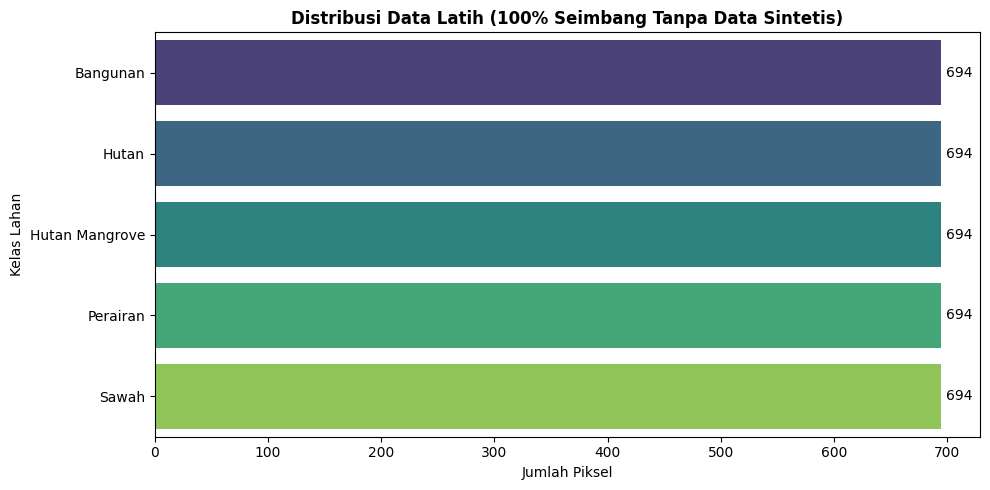

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

# Memuat dataset dan membuang baris yang memiliki nilai kosong
df = pd.read_csv('dataset_training.csv').dropna()

# Pemisahan fitur spektral/indeks (X) dan variabel target (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Stratified Train-Test Split (80:20) untuk menjaga proporsi data uji tetap objektif
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Distribusi Data Latih (Sebelum Balancing):")
print(y_train.value_counts())

# Undersampling Murni: Memangkas kelas mayoritas agar setara dengan kelas terkecil secara otomatis
under_sampler = RandomUnderSampler(sampling_strategy='auto', random_state=42)
X_train_bal, y_train_bal = under_sampler.fit_resample(X_train, y_train)

print("\nDistribusi Data Latih (Setelah Undersampling Murni):")
print(y_train_bal.value_counts())

# Visualisasi distribusi kelas setelah diseimbangkan
plt.figure(figsize=(10, 5))
grafik = sns.countplot(
    y=y_train_bal, 
    palette='viridis', 
    order=y_train_bal.value_counts().index,
    hue=y_train_bal,
    legend=False
)
plt.title('Distribusi Data Latih (100% Seimbang Tanpa Data Sintetis)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Piksel')
plt.ylabel('Kelas Lahan')

for p in grafik.patches:
    width = p.get_width()
    grafik.annotate(f'{int(width)}', 
                    (width + 5, p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.show()

## Modeling

Tahap ini merupakan inti dari seluruh proses pengembangan, di mana algoritma *Machine Learning* dilatih menggunakan data spektral yang telah disiapkan agar mampu mengenali karakteristik unik permukaan bumi dan melakukan klasifikasi tutupan lahan secara otomatis. 

Algoritma utama yang digunakan dalam penelitian ini adalah **Random Forest Classifier**, sebuah metode *ensemble learning* yang sangat tangguh dalam menangani data geospasial karena mampu memodelkan hubungan non-linear yang kompleks antar-band spektral tanpa mudah mengalami *overfitting*.

Model dilatih menggunakan 8 fitur independen (6 band spektral mentah dan 2 indeks kalkulasi, yakni NDVI dan NDWI) pada dataset latih yang telah 100% diseimbangkan (tepat 694 piksel per kelas). Karena distribusi kelas kini sudah merata secara fisik menggunakan data observasi satelit murni tanpa kloning sintetis (SMOTE), algoritma tidak lagi memerlukan parameter pembobotan kelas paksa (*algorithmic class weighting*). Konfigurasi parameter seperti kedalaman pohon (*max_depth*) disesuaikan secara proporsional agar model mampu mengekstrak pola batas yang rumit, seperti perbedaan serapan SWIR 2 pada Hutan Mangrove dan Hutan Biasa.

### Konsep Alur Kerja Pemodelan

Proses pemodelan dibagi menjadi dua fase utama untuk memastikan model yang dihasilkan tidak hanya sekadar menghafal data latihan, melainkan juga andal saat memprediksi area baru:

- **Fase Pelatihan (Training):** Algoritma *Random Forest Classifier* dilatih secara eksklusif menggunakan data latih hasil *undersampling* murni. Karena dataset pelatihan sudah 100% seimbang secara jumlah (masing-masing 694 piksel per kelas), algoritma dibiarkan belajar secara natural tanpa perlu intervensi pembobotan kelas. Pada tahap ini, model memetakan pola aturan (*decision rules*) berdasarkan 8 fitur kunci (Band 2, Band 3, Band 4, Band 8A, Band 11, Band 12, NDVI, dan NDWI) untuk mengenali setiap kelas lahan.
- **Fase Pengujian (Testing):** Model yang telah selesai dibangun kemudian diuji kemampuannya menggunakan sisa 20% data uji. Data uji ini sangat krusial karena ia tetap dibiarkan dalam kondisi tidak seimbang (*imbalanced*) sesuai dengan distribusi alam aslinya, dan disembunyikan sepenuhnya selama masa pelatihan. Langkah ini bertujuan untuk mengukur performa objektif dan kejujuran model saat dihadapkan pada skenario dunia nyata yang sebenarnya.


### Rincian Data Latih dan Uji

Sebelum proses pelatihan dimulai, penting untuk meninjau kembali rincian dimensi, struktur, serta distribusi kelas dari data latih yang telah diseimbangkan dan data uji yang akan digunakan sebagai validator performa model.

In [7]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Menampilkan informasi dimensi data
print("Dimensi Dataset Pemodelan:")
print(f"Jumlah sampel data latih : {X_train_bal.shape[0]:,}")
print(f"Jumlah sampel data uji   : {X_test.shape[0]:,}")
print(f"Jumlah fitur             : {X_train_bal.shape[1]} (Band_2, Band_3, Band_4, Band_8A, Band_11, Band_12, NDVI, NDWI)\n")

print("Komposisi Kelas Data Latih:")
print(y_train_bal.value_counts())

print("\nSamples Data Latih:")
display(X_train_bal.head())

Dimensi Dataset Pemodelan:
Jumlah sampel data latih : 3,470
Jumlah sampel data uji   : 10,367
Jumlah fitur             : 8 (Band_2, Band_3, Band_4, Band_8A, Band_11, Band_12, NDVI, NDWI)

Komposisi Kelas Data Latih:
Class
Bangunan          694
Hutan             694
Hutan Mangrove    694
Perairan          694
Sawah             694
Name: count, dtype: int64

Samples Data Latih:


,Band_2,Band_3,Band_4,Band_8A,Band_11,Band_12,NDVI,NDWI
47593,943.800000,1170.333333,1455.666667,2098.250000,2538.000,2263.000000,0.180810,-0.283890
47183,1011.000000,1166.333333,1323.900000,1842.000000,2543.800,2513.285714,0.163650,-0.224598
48508,920.250000,1129.200000,1509.000000,2157.666667,3077.800,2934.666667,0.176909,-0.312902
48414,741.500000,928.769231,991.090909,1872.625000,1934.375,1739.571429,0.307829,-0.336924
46995,688.166667,912.071429,1357.000000,2124.125000,3172.500,2839.333333,0.220367,-0.399201


### Proses Pelatihan Model (Training)

Pada tahap ini, algoritma *Random Forest* diinisialisasi untuk mempelajari pola hubungan antara 8 fitur karakteristik spektral (6 band mentah dan 2 indeks kalkulasi) dengan kelas tutupan lahan pada dataset latih. Konfigurasi model menggunakan beberapa parameter kunci dengan alasan teknis berikut:

| Parameter | Nilai / Konfigurasi | Alasan Teknis dan Fungsi |
|---|---|---|
| **n_estimators** | `100` | Membangun 100 pohon keputusan (*decision trees*) secara paralel. Jumlah ini merupakan titik optimal standar untuk menangkap pola spektral yang kompleks tanpa membebani memori komputasi secara berlebihan. |
| **max_depth** | `15` | Membatasi kedalaman maksimal setiap pohon. Angka 15 cukup dalam untuk mengekstrak pola batas yang rumit (seperti perbedaan serapan air pada Mangrove vs Hutan Biasa), sekaligus mencegah model menghafal data (*overfitting*). |
| **min_samples_leaf** | `2` | Menetapkan batas minimal 2 sampel pada ujung cabang terakhir pohon keputusan. Ini mencegah algoritma membuat aturan ekstrem yang hanya berlaku untuk 1 piksel spesifik, sehingga model lebih general dan kebal terhadap *noise*. |
| **random_state** | `42` | Berfungsi sebagai pengunci keacakan (*seed*). Parameter ini memastikan hasil pembuatan pohon akan selalu konsisten setiap kali kode dijalankan ulang (*reproducible*). |
| **n_jobs** | `-1` | Memerintahkan komputer untuk menggunakan seluruh inti prosesor (*CPU cores*) secara maksimal untuk mempercepat waktu komputasi pelatihan model. |

In [8]:
from sklearn.ensemble import RandomForestClassifier

print("Memulai proses pelatihan model Random Forest...")

# Inisialisasi model 
rf_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=15,             # Kedalaman ditingkatkan untuk menangkap pola batas yang kompleks
    min_samples_leaf=2,       
    random_state=42, 
    n_jobs=-1
)

# Pelatihan model menggunakan data hasil Undersampling Murni (694 piksel per kelas)
rf_model.fit(X_train_bal, y_train_bal)

print("Proses pelatihan selesai. Model berhasil dibangun.")

Memulai proses pelatihan model Random Forest...
Proses pelatihan selesai. Model berhasil dibangun.


### MODEL
Setelah dilakukannya training, didapatkanlah model seperti berikut :

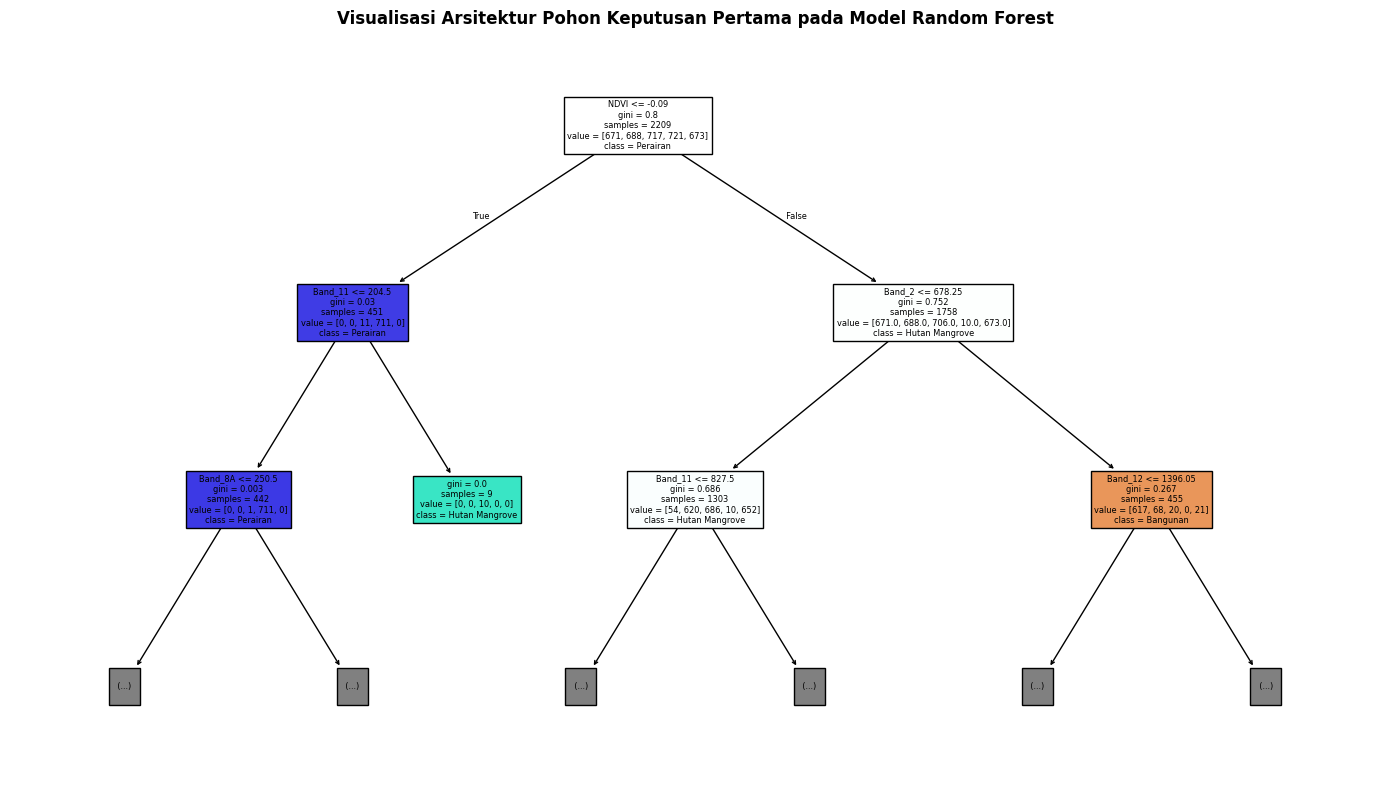

In [9]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Mengekstrak estimator (pohon keputusan) pertama dari ansambel Random Forest
pohon_pertama = rf_model.estimators_[0]

plt.figure(figsize=(14, 8))
plot_tree(
    pohon_pertama, 
    feature_names=['Band_2', 'Band_3', 'Band_4', 'Band_8A', 'Band_11', 'Band_12', 'NDVI', 'NDWI'], 
    class_names=list(rf_model.classes_), 
    filled=True, 
    max_depth=2
) 

plt.title("Visualisasi Arsitektur Pohon Keputusan Pertama pada Model Random Forest", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### Pengujian dan Evaluasi Model

Setelah proses pelatihan selesai, model diuji menggunakan data uji untuk mengevaluasi performa klasifikasinya secara menyeluruh. Pengujian ini penting untuk melihat kemampuan generalisasi model terhadap data baru yang belum pernah dipelajari sebelumnya.

Menjalankan prediksi pada data uji...

Akurasi Global Model: 97.73%

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

      Bangunan       0.98      0.98      0.98       478
         Hutan       0.98      0.95      0.96       856
Hutan Mangrove       0.62      0.87      0.72       173
      Perairan       1.00      0.98      0.99      8326
         Sawah       0.82      0.96      0.89       534

      accuracy                           0.98     10367
     macro avg       0.88      0.95      0.91     10367
  weighted avg       0.98      0.98      0.98     10367



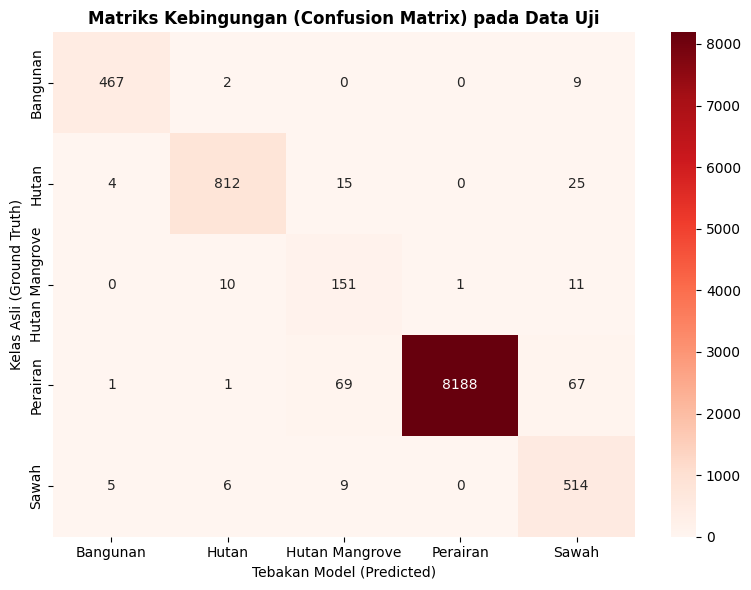


Proses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'


In [10]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

print("Menjalankan prediksi pada data uji...")

# Evaluasi model menggunakan data uji murni yang independen dari proses latih
y_pred = rf_model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)

print(f"\nAkurasi Global Model: {akurasi * 100:.2f}%")
print("\nLaporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred))

# Membongkar salah tebak model dengan Matriks Kebingungan
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Reds', 
    xticklabels=rf_model.classes_, 
    yticklabels=rf_model.classes_
)
plt.title('Matriks Kebingungan (Confusion Matrix) pada Data Uji', fontweight='bold')
plt.ylabel('Kelas Asli (Ground Truth)')
plt.xlabel('Tebakan Model (Predicted)')
plt.tight_layout()
plt.show()

# Ekspor hasil pemodelan ke berkas biner pkl
joblib.dump(rf_model, 'model_rf.pkl')
print("\nProses selesai. Model berhasil disimpan sebagai 'model_rf.pkl'")

## DEPLOYMENT


In [11]:
import os
import rasterio
import numpy as np
import joblib

input_tif = 'Sentinel2_Area.tif'
output_tif = 'Hasil_Klasifikasi_LULC.tif'
file_model = 'model_rf.pkl'

if os.path.exists(output_tif):
    print(f"File output '{output_tif}' sudah tersedia. Proses inferensi raster dilewati.")
else:
    print(f"Memuat model Random Forest dari '{file_model}'...")
    rf_model = joblib.load(file_model) 

    print("Membuka citra satelit input...")
    with rasterio.open(input_tif) as src:
        meta = src.meta
        # Membaca 8 Fitur secara berurutan (B2, B3, B4, B8A, B11, B12, NDVI, NDWI)
        img_data = src.read([1, 2, 3, 4, 5, 6, 7, 8]) 
        print(f"Dimensi citra input: {img_data.shape} (Band, Baris, Kolom)")

    # Transformasi matriks 3D menjadi format tabel tabular (2D) untuk input model
    n_bands, baris, kolom = img_data.shape
    img_flatten = img_data.reshape(n_bands, -1).T 

    # Masking piksel background bernilai 0 di luar area kajian
    mask = (img_flatten[:, 0] > 0)
    data_valid = img_flatten[mask]

    print(f"Melakukan klasifikasi pada {data_valid.shape[0]:,} piksel data valid...")
    prediksi_valid = rf_model.predict(data_valid)

    print("Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...")

    # Konversi label kategori string menjadi nilai integer biner untuk format raster GeoTIFF
    kamus_warna = {
        'Perairan': 1,
        'Hutan': 2,
        'Hutan Mangrove': 3,
        'Sawah': 4,
        'Bangunan': 5
    }
    prediksi_angka = np.vectorize(kamus_warna.get)(prediksi_valid)

    # Rekonstruksi bentuk data kembali ke dimensi spasial asli (Baris x Kolom)
    peta_hasil = np.zeros(baris * kolom, dtype=np.uint8)
    peta_hasil[mask] = prediksi_angka
    peta_hasil_2d = peta_hasil.reshape(baris, kolom)

    # Pembaruan metadata file output (1 Band, Format UInt8, NoData = 0)
    meta.update(count=1, dtype=rasterio.uint8, nodata=0) 

    print("Menulis file output raster...")
    with rasterio.open(output_tif, 'w', **meta) as dst:
        dst.write(peta_hasil_2d, 1)

    print(f"Proses selesai. File klasifikasi spasial disimpan di: {output_tif}")

Memuat model Random Forest dari 'model_rf.pkl'...
Membuka citra satelit input...
Dimensi citra input: (8, 2055, 3337) (Band, Baris, Kolom)
Melakukan klasifikasi pada 6,857,532 piksel data valid...


C:\Users\mappattiro\kal\kal\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Proses klasifikasi selesai. Melakukan pemetaan ulang nilai spektral...
Menulis file output raster...
Proses selesai. File klasifikasi spasial disimpan di: Hasil_Klasifikasi_LULC.tif


### HASIL STREAMLIT

Untuk melihat hasil pemetaan, masuk ke link berikut :
https://lulc-jatim-app-uts.streamlit.app/